In [ ]:
install.packages("reshape2")
require(foreign)
require(MASS)
require(ggplot2)
library(reshape2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
df_raw <- read.csv("kidney_disease_dataset.csv")
head(df_raw)

,Age.of.the.patient,Blood.pressure..mm.Hg.,Specific.gravity.of.urine,Albumin.in.urine,Sugar.in.urine,Red.blood.cells.in.urine,Pus.cells.in.urine,Pus.cell.clumps.in.urine,Bacteria.in.urine,Random.blood.glucose.level..mg.dl.,⋯,Smoking.status,Body.Mass.Index..BMI.,Physical.activity.level,Duration.of.diabetes.mellitus..years.,Duration.of.hypertension..years.,Cystatin.C.level,Urinary.sediment.microscopy.results,C.reactive.protein..CRP..level,Interleukin.6..IL.6..level,Target
,<int>,<int>,<dbl>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,⋯,<chr>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<chr>
1,54,167,1.023,1,4,normal,abnormal,not present,not present,96,⋯,yes,25.3,low,4,16,0.67,normal,4.88,10.23,No_Disease
2,42,127,1.023,3,2,normal,normal,not present,present,73,⋯,no,20.6,moderate,3,13,0.55,abnormal,4.49,13.11,Low_Risk
3,38,148,1.016,0,0,abnormal,normal,not present,not present,77,⋯,no,38.4,high,11,23,2.37,abnormal,4.57,13.27,No_Disease
4,7,98,1.017,4,0,abnormal,normal,not present,present,225,⋯,no,24.7,high,24,3,2.54,abnormal,8.57,12.36,No_Disease
5,67,174,1.015,1,1,normal,abnormal,not present,not present,376,⋯,yes,17.6,high,22,24,1.90,normal,6.75,1.46,No_Disease
6,14,92,1.006,4,2,abnormal,abnormal,not present,present,371,⋯,yes,23.7,moderate,26,12,2.81,normal,2.33,2.98,No_Disease


In [ ]:
str(df_raw)

'data.frame':	20538 obs. of  43 variables:
 $ Age.of.the.patient                         : int  54 42 38 7 67 14 9 67 42 23 ...
 $ Blood.pressure..mm.Hg.                     : int  167 127 148 98 174 92 156 100 138 127 ...
 $ Specific.gravity.of.urine                  : num  1.02 1.02 1.02 1.02 1.01 ...
 $ Albumin.in.urine                           : int  1 3 0 4 1 4 2 5 4 2 ...
 $ Sugar.in.urine                             : int  4 2 0 0 1 2 0 3 4 4 ...
 $ Red.blood.cells.in.urine                   : chr  "normal" "normal" "abnormal" "abnormal" ...
 $ Pus.cells.in.urine                         : chr  "abnormal" "normal" "normal" "normal" ...
 $ Pus.cell.clumps.in.urine                   : chr  "not present" "not present" "not present" "not present" ...
 $ Bacteria.in.urine                          : chr  "not present" "present" "not present" "present" ...
 $ Random.blood.glucose.level..mg.dl.         : int  96 73 77 225 376 371 255 260 352 196 ...
 $ Blood.urea..mg.dl.                

In [ ]:
nrow(df_raw)

[1] 20538

In [ ]:
install.packages("dplyr")
library(dplyr)
df_raw <- distinct(df_raw)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
colnames(df_raw)

[1] "Age.of.the.patient"                         
 [2] "Blood.pressure..mm.Hg."                     
 [3] "Specific.gravity.of.urine"                  
 [4] "Albumin.in.urine"                           
 [5] "Sugar.in.urine"                             
 [6] "Red.blood.cells.in.urine"                   
 [7] "Pus.cells.in.urine"                         
 [8] "Pus.cell.clumps.in.urine"                   
 [9] "Bacteria.in.urine"                          
[10] "Random.blood.glucose.level..mg.dl."         
[11] "Blood.urea..mg.dl."                         
[12] "Serum.creatinine..mg.dl."                   
[13] "Sodium.level..mEq.L."                       
[14] "Potassium.level..mEq.L."                    
[15] "Hemoglobin.level..gms."                     
[16] "Packed.cell.volume...."                     
[17] "White.blood.cell.count..cells.cumm."        
[18] "Red.blood.cell.count..millions.cumm."       
[19] "Hypertension..yes.no."                      
[20] "Diabetes.mellitus..yes.no."                 
[21] "Coronary.artery.disease..yes.no."           
[22] "Appetite..good.poor."                       
[23] "Pedal.edema..yes.no."                       
[24] "Anemia..yes.no."                            
[25] "Estimated.Glomerular.Filtration.Rate..eGFR."
[26] "Urine.protein.to.creatinine.ratio"          
[27] "Urine.output..ml.day."                      
[28] "Serum.albumin.level"                        
[29] "Cholesterol.level"                          
[30] "Parathyroid.hormone..PTH..level"            
[31] "Serum.calcium.level"                        
[32] "Serum.phosphate.level"                      
[33] "Family.history.of.chronic.kidney.disease"   
[34] "Smoking.status"                             
[35] "Body.Mass.Index..BMI."                      
[36] "Physical.activity.level"                    
[37] "Duration.of.diabetes.mellitus..years."      
[38] "Duration.of.hypertension..years."           
[39] "Cystatin.C.level"                           
[40] "Urinary.sediment.microscopy.results"        
[41] "C.reactive.protein..CRP..level"             
[42] "Interleukin.6..IL.6..level"                 
[43] "Target"

In [ ]:
sum(is.na(df_raw))

[1] 0

In [ ]:
df_rawcorr <- df_raw[, sapply(df_raw, is.numeric)]
correlation_matrix <- cor(df_rawcorr)
correlation_matrix

,Age.of.the.patient,Blood.pressure..mm.Hg.,Specific.gravity.of.urine,Albumin.in.urine,Sugar.in.urine,Random.blood.glucose.level..mg.dl.,Blood.urea..mg.dl.,Serum.creatinine..mg.dl.,Sodium.level..mEq.L.,Potassium.level..mEq.L.,⋯,Cholesterol.level,Parathyroid.hormone..PTH..level,Serum.calcium.level,Serum.phosphate.level,Body.Mass.Index..BMI.,Duration.of.diabetes.mellitus..years.,Duration.of.hypertension..years.,Cystatin.C.level,C.reactive.protein..CRP..level,Interleukin.6..IL.6..level
Age.of.the.patient,1.0000000000,-0.0019519566,-0.002532050,-4.592105e-03,0.0055048046,-0.0111692587,0.0138288276,-0.008577779,1.316268e-02,0.0016379932,⋯,-0.0238084406,-0.0074807043,0.0086821207,0.0036859516,-0.0144634830,0.0021928158,-0.0066495926,-0.0202122714,-1.811063e-03,-0.003397930
Blood.pressure..mm.Hg.,-0.0019519566,1.0000000000,-0.014749826,-5.509242e-03,0.0028085123,-0.0025745601,-0.0042569535,-0.009284109,-9.233092e-04,0.0010059523,⋯,0.0058395365,0.0117684994,-0.0015394213,-0.0037098933,0.0053004437,0.0076395386,0.0037730869,-0.0047794219,6.387363e-03,-0.004536746
Specific.gravity.of.urine,-0.0025320504,-0.0147498261,1.000000000,3.637815e-03,-0.0046648318,0.0131214401,-0.0113209041,-0.004741966,1.063451e-02,-0.0052562274,⋯,-0.0120765625,0.0039702768,-0.0086516081,0.0074772630,0.0151378407,-0.0079933755,0.0045097563,0.0034626561,2.535867e-03,-0.001418668
Albumin.in.urine,-0.0045921049,-0.0055092425,0.003637815,1.000000e+00,-0.0003687060,-0.0002764574,-0.0095815511,0.013647525,3.442082e-04,0.0045349763,⋯,-0.0048837636,-0.0063406408,0.0040835291,0.0074910785,0.0006899723,0.0014232075,-0.0017388001,-0.0087124082,-1.194614e-02,0.001842491
Sugar.in.urine,0.0055048046,0.0028085123,-0.004664832,-3.687060e-04,1.0000000000,0.0019031754,0.0035781295,-0.005652919,1.790580e-02,-0.0114448412,⋯,-0.0022329442,0.0063437280,0.0006891096,-0.0092467242,0.0016570234,-0.0070305728,0.0087313110,-0.0054685389,1.304235e-02,-0.013104379
Random.blood.glucose.level..mg.dl.,-0.0111692587,-0.0025745601,0.013121440,-2.764574e-04,0.0019031754,1.0000000000,-0.0013908006,0.003155951,-1.454881e-03,-0.0104082414,⋯,0.0097378594,0.0007279794,0.0035528148,0.0085899104,0.0124749925,0.0055721496,0.0019345748,-0.0076484927,1.068588e-03,0.007007732
Blood.urea..mg.dl.,0.0138288276,-0.0042569535,-0.011320904,-9.581551e-03,0.0035781295,-0.0013908006,1.0000000000,0.009765599,-3.982320e-03,0.0037102311,⋯,-0.0009811313,0.0017659105,0.0055283524,-0.0119605863,0.0055266799,0.0012971564,-0.0071240884,-0.0041712977,1.443134e-03,0.002726993
Serum.creatinine..mg.dl.,-0.0085777786,-0.0092841089,-0.004741966,1.364752e-02,-0.0056529192,0.0031559512,0.0097655988,1.000000000,-6.109501e-03,0.0078893040,⋯,0.0046721483,0.0043697018,-0.0088292663,0.0060157417,0.0033280264,-0.0043927878,0.0012115549,0.0017883088,-2.762730e-03,0.006295520
Sodium.level..mEq.L.,0.0131626845,-0.0009233092,0.010634511,3.442082e-04,0.0179057962,-0.0014548815,-0.0039823202,-0.006109501,1.000000e+00,-0.0063096132,⋯,-0.0031716480,-0.0117290643,-0.0001115755,0.0048151856,0.0151763712,0.0056730206,-0.0040153530,0.0037629362,-2.730729e-05,0.006599907
Potassium.level..mEq.L.,0.0016379932,0.0010059523,-0.005256227,4.534976e-03,-0.0114448412,-0.0104082414,0.0037102311,0.007889304,-6.309613e-03,1.0000000000,⋯,-0.0046898402,-0.0004275049,0.0024397456,0.0025176618,0.0020501840,-0.0032160938,-0.0137719668,-0.0009604403,4.330647e-03,-0.001931564


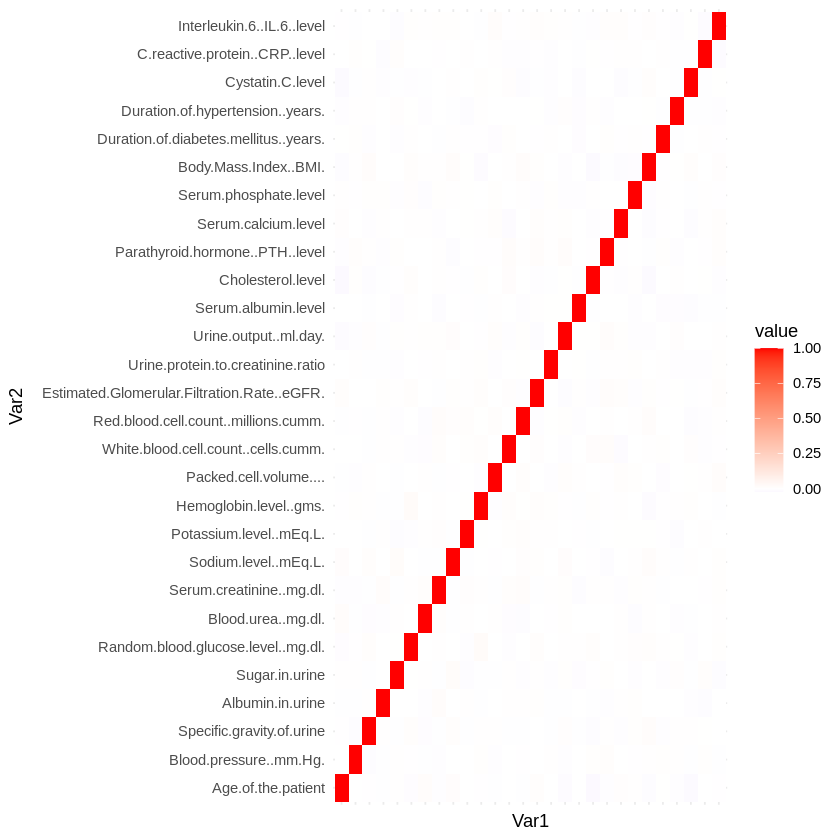

In [ ]:
melted_cor <- melt(correlation_matrix)
ggplot(melted_cor, aes(Var1, Var2, fill = value)) +
  geom_tile() +
  theme_minimal() +
  scale_fill_gradient2(midpoint = 0, low = "blue", mid = "white", high = "red") + theme(axis.text.x = element_blank())

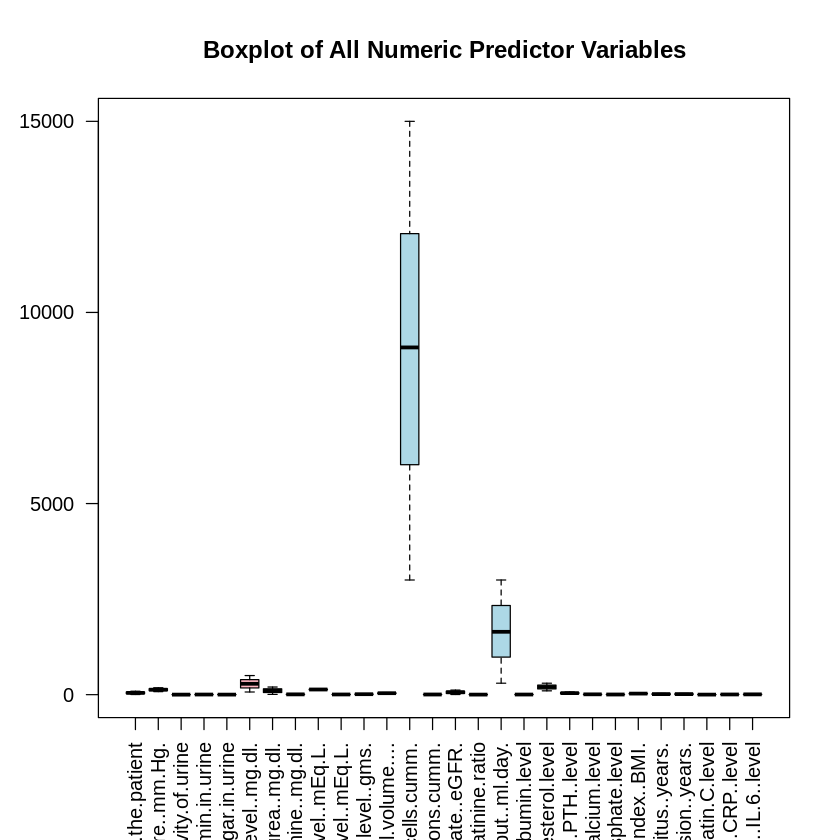

In [ ]:
df_rawbox <- df_raw[, sapply(df_raw, is.numeric)]
boxplot(df_rawbox,
        col = c("lightblue", "lightpink", "lightgreen", "lightblue"),
        main = "Boxplot of All Numeric Predictor Variables",
        border = "black",
        notch = FALSE,
        las = 2)

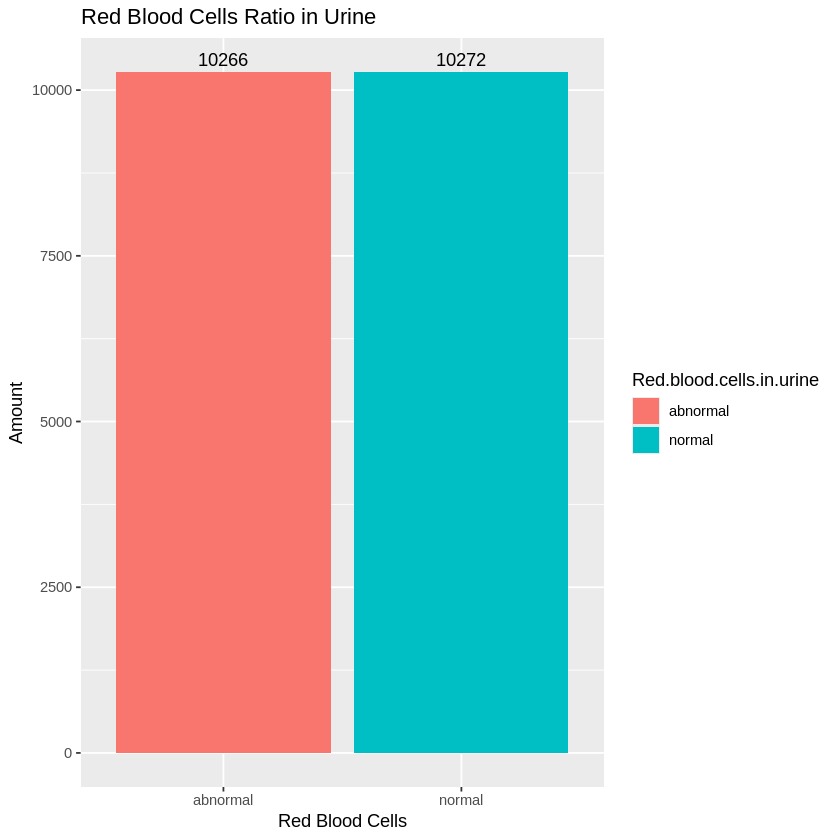

In [ ]:
ggplot(df_raw, aes(x = Red.blood.cells.in.urine, fill = Red.blood.cells.in.urine)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Red Blood Cells") + ylab("Amount") +
  ggtitle("Red Blood Cells Ratio in Urine")

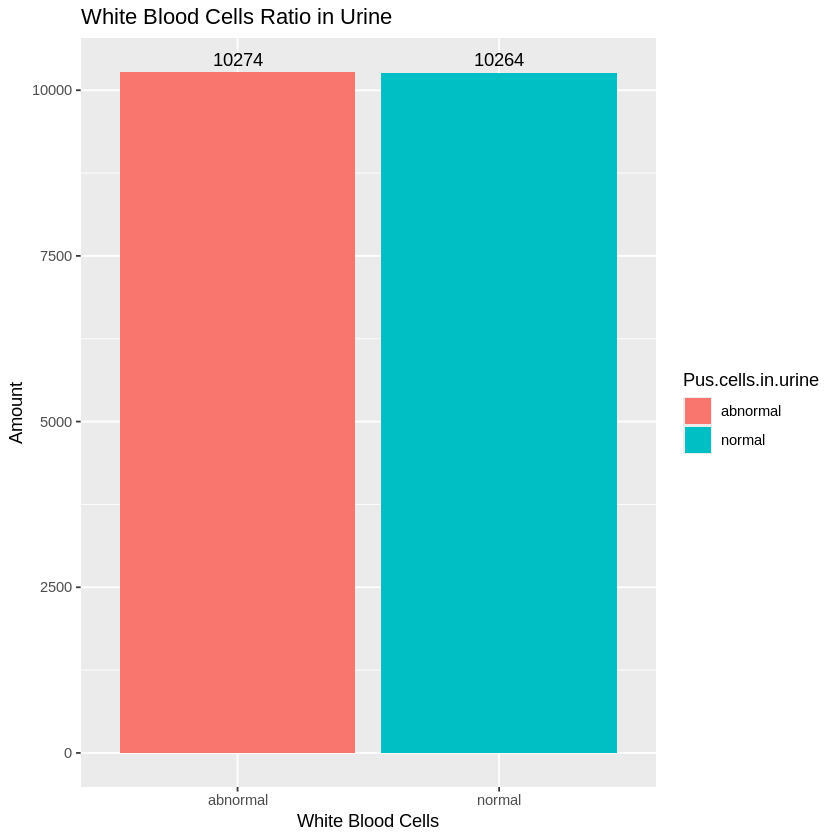

In [ ]:
ggplot(df_raw, aes(x = Pus.cells.in.urine, fill = Pus.cells.in.urine)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("White Blood Cells") + ylab("Amount") +
  ggtitle("White Blood Cells Ratio in Urine")

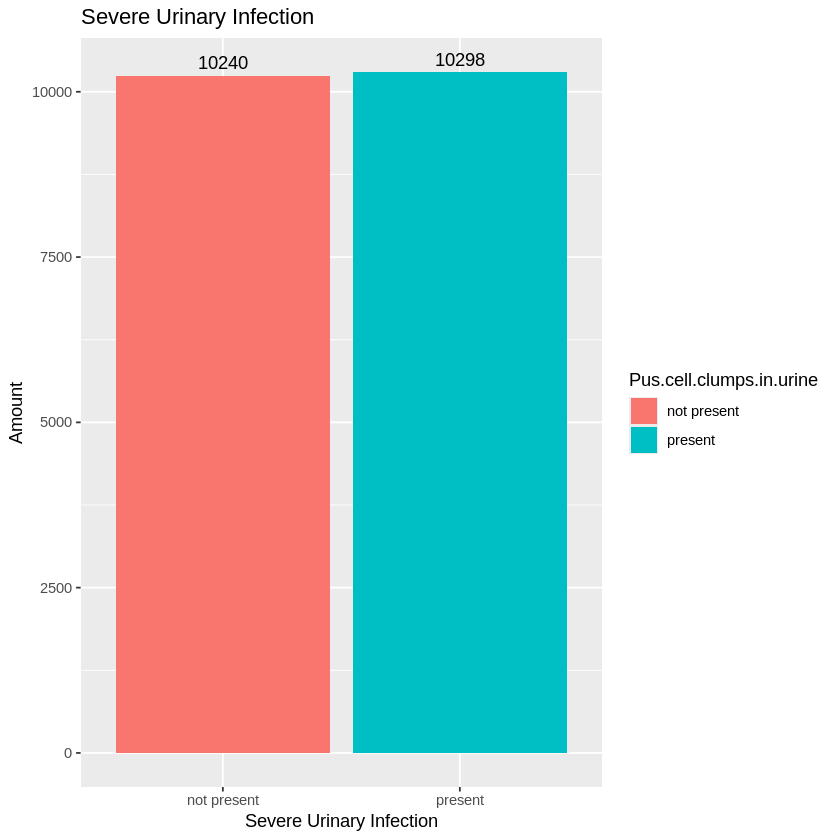

In [ ]:
ggplot(df_raw, aes(x = Pus.cell.clumps.in.urine , fill = Pus.cell.clumps.in.urine )) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Severe Urinary Infection") + ylab("Amount") +
  ggtitle("Severe Urinary Infection")

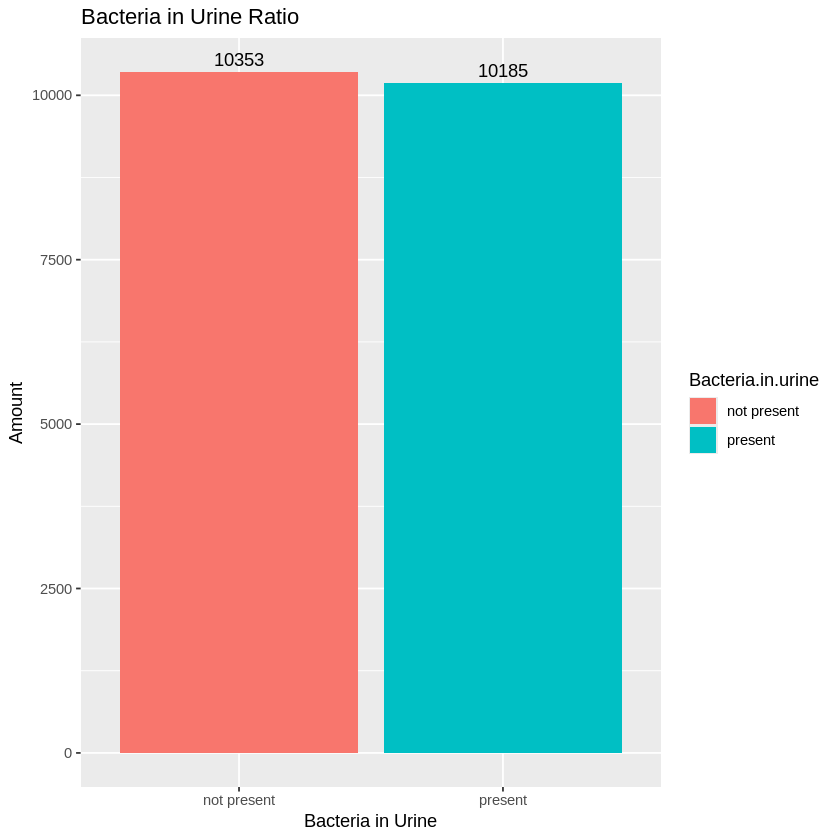

In [ ]:
ggplot(df_raw, aes(x = Bacteria.in.urine  , fill = Bacteria.in.urine)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Bacteria in Urine") + ylab("Amount") +
  ggtitle("Bacteria in Urine Ratio")

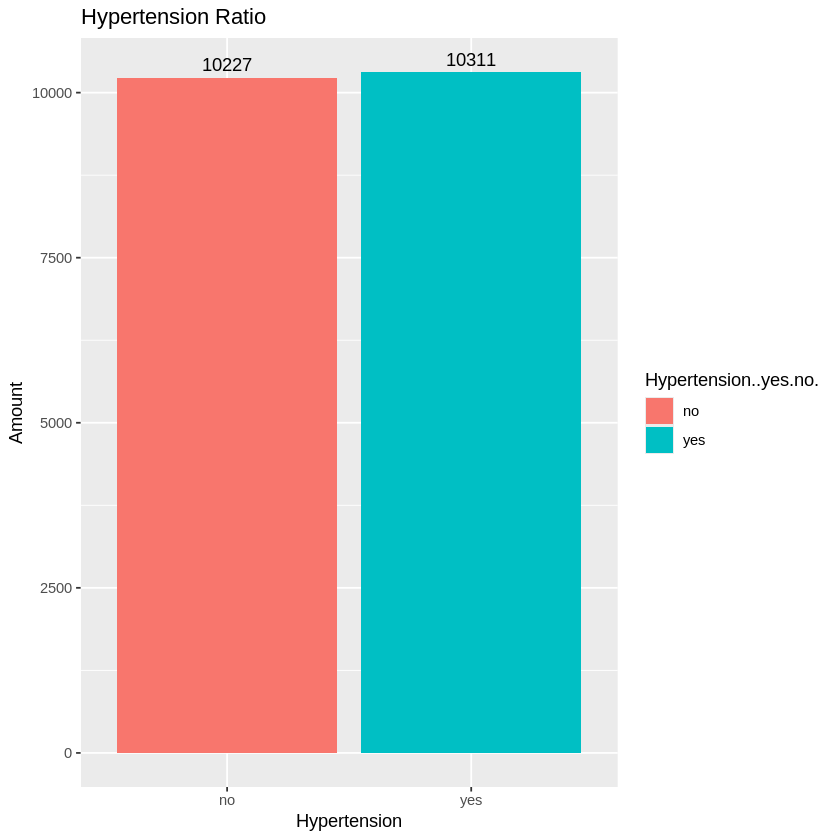

In [ ]:
ggplot(df_raw, aes(x = Hypertension..yes.no.  , fill = Hypertension..yes.no.  )) +
  geom_bar() + xlab("Hypertension") + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + ylab("Amount") +
  ggtitle("Hypertension Ratio")

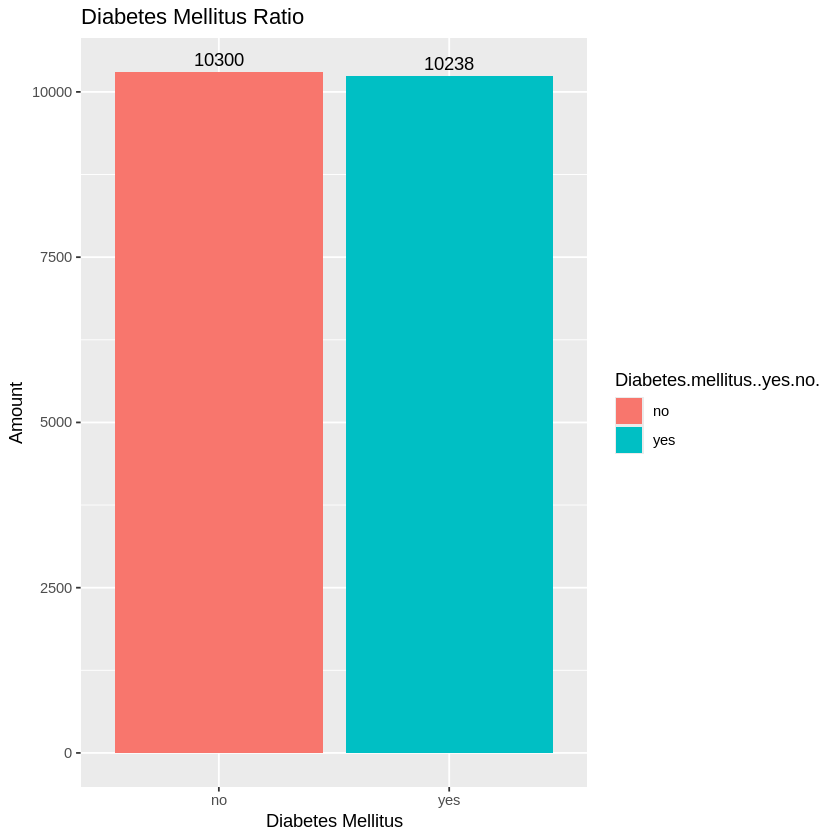

In [ ]:
ggplot(df_raw, aes(x = Diabetes.mellitus..yes.no., fill = Diabetes.mellitus..yes.no.)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Diabetes Mellitus") + ylab("Amount") +
  ggtitle("Diabetes Mellitus Ratio")

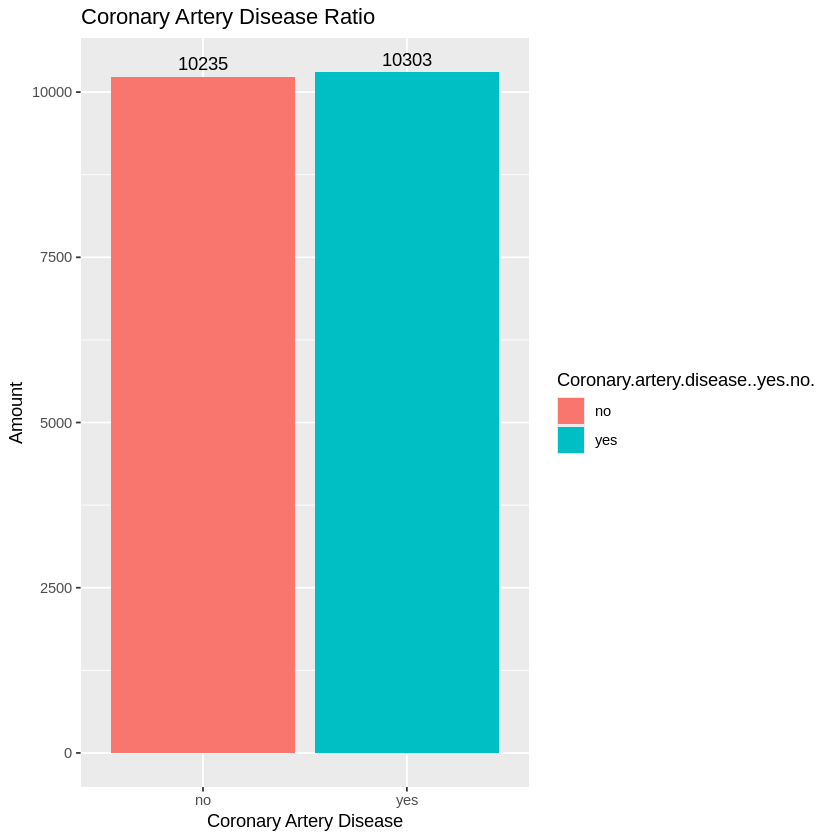

In [ ]:
ggplot(df_raw, aes(x = Coronary.artery.disease..yes.no., fill = Coronary.artery.disease..yes.no.)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Coronary Artery Disease") + ylab("Amount") +
  ggtitle("Coronary Artery Disease Ratio")

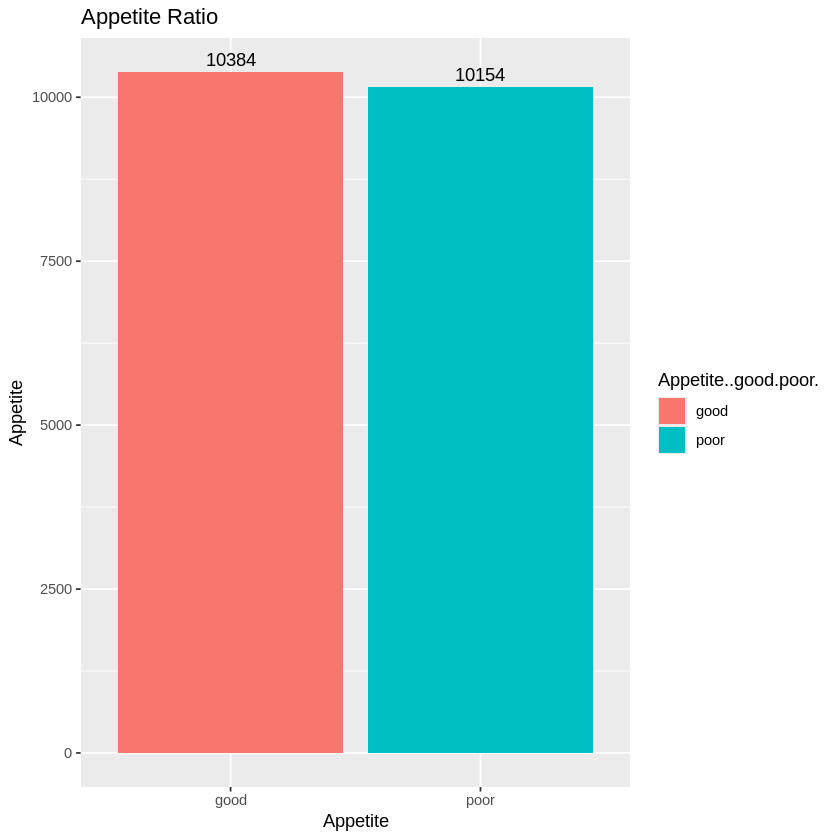

In [ ]:
ggplot(df_raw, aes(x = Appetite..good.poor., fill = Appetite..good.poor.)) +
  geom_bar() + xlab("Appetite") + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5)+ ylab("Appetite") +
  ggtitle("Appetite Ratio")

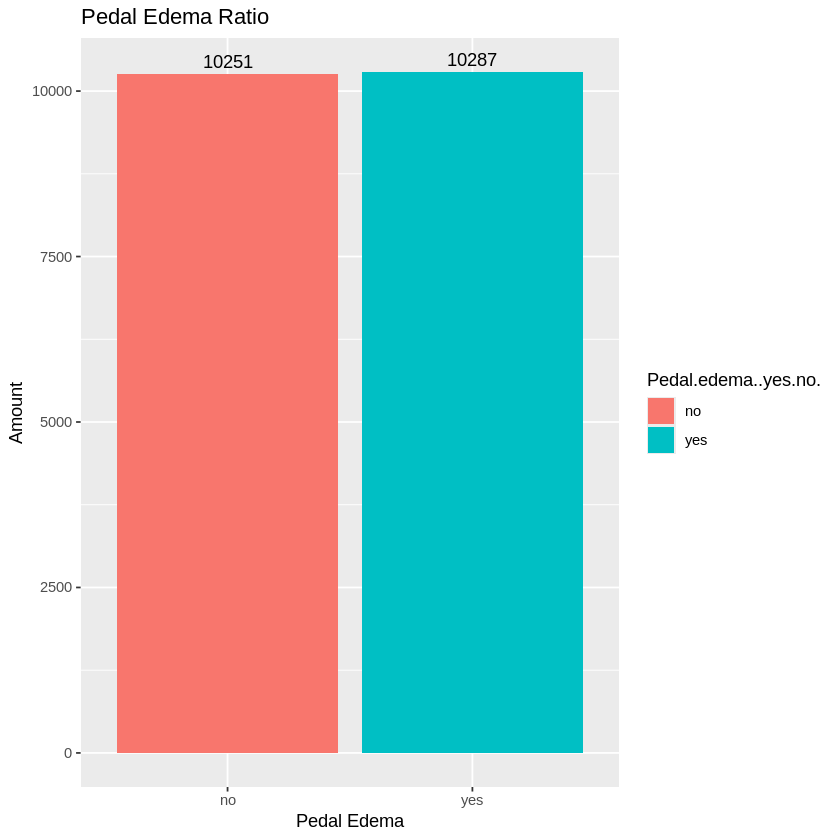

In [ ]:
ggplot(df_raw, aes(x = Pedal.edema..yes.no., fill = Pedal.edema..yes.no.)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) +  xlab("Pedal Edema") + ylab("Amount") +
  ggtitle("Pedal Edema Ratio")

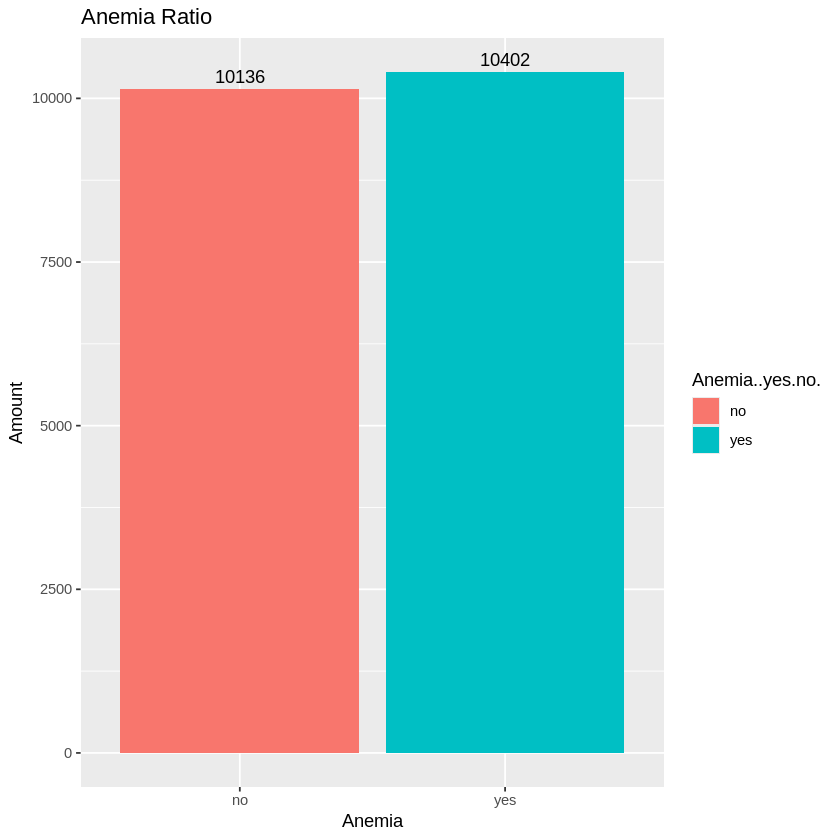

In [ ]:
ggplot(df_raw, aes(x = Anemia..yes.no., fill = Anemia..yes.no.)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Anemia") + ylab("Amount") +
  ggtitle("Anemia Ratio")

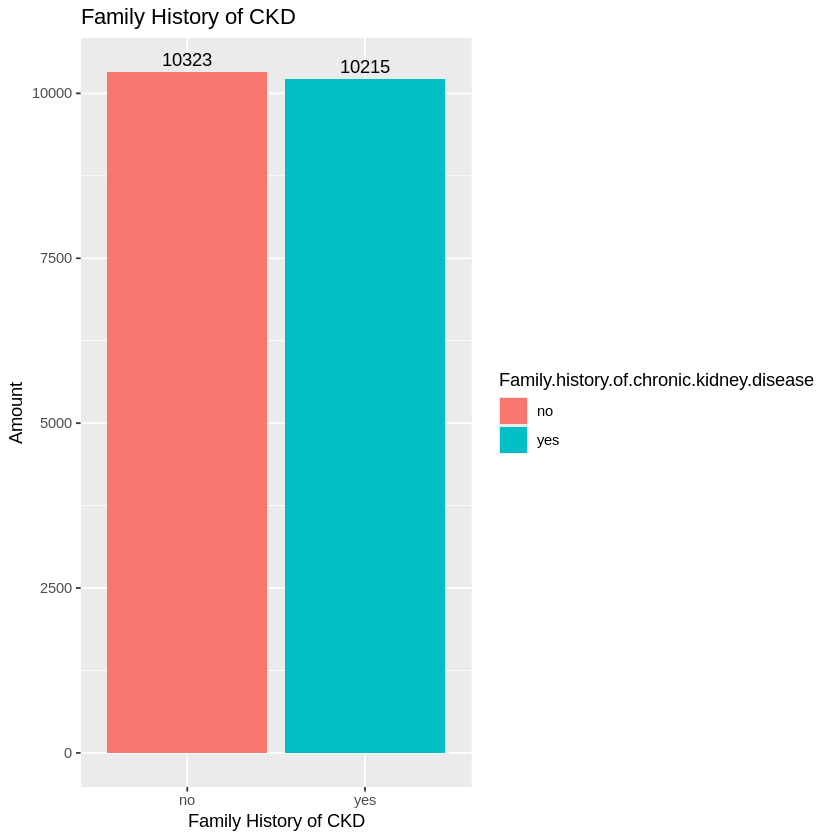

In [ ]:
ggplot(df_raw, aes(x = Family.history.of.chronic.kidney.disease, fill = Family.history.of.chronic.kidney.disease)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Family History of CKD") + ylab("Amount") +
  ggtitle("Family History of CKD")

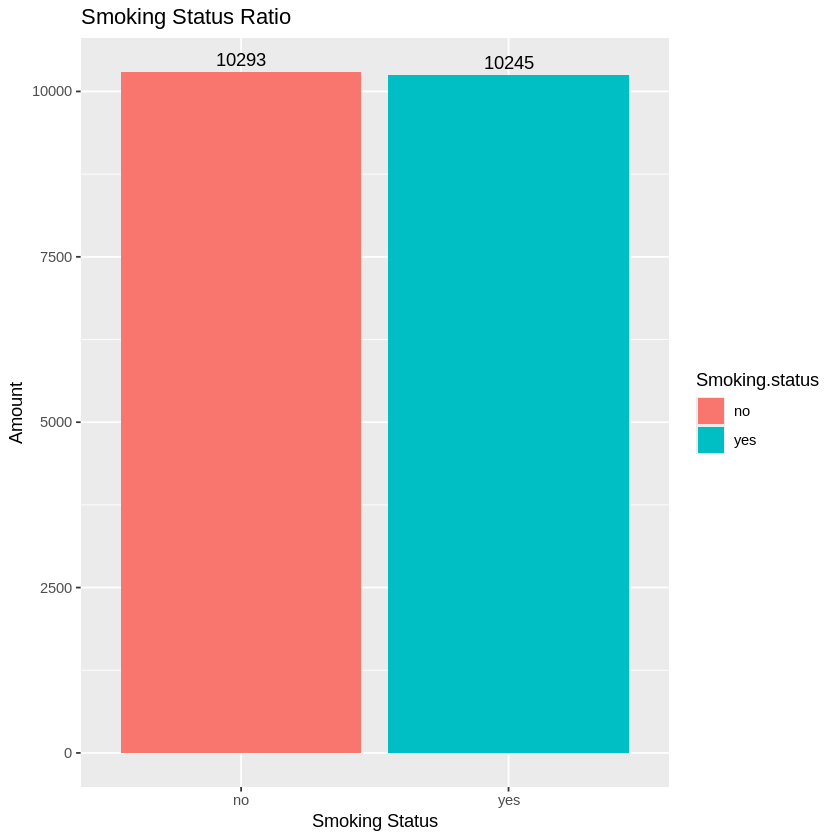

In [ ]:
ggplot(df_raw, aes(x = Smoking.status, fill = Smoking.status)) +
  geom_bar() + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + xlab("Smoking Status") + ylab("Amount") +
  ggtitle("Smoking Status Ratio")

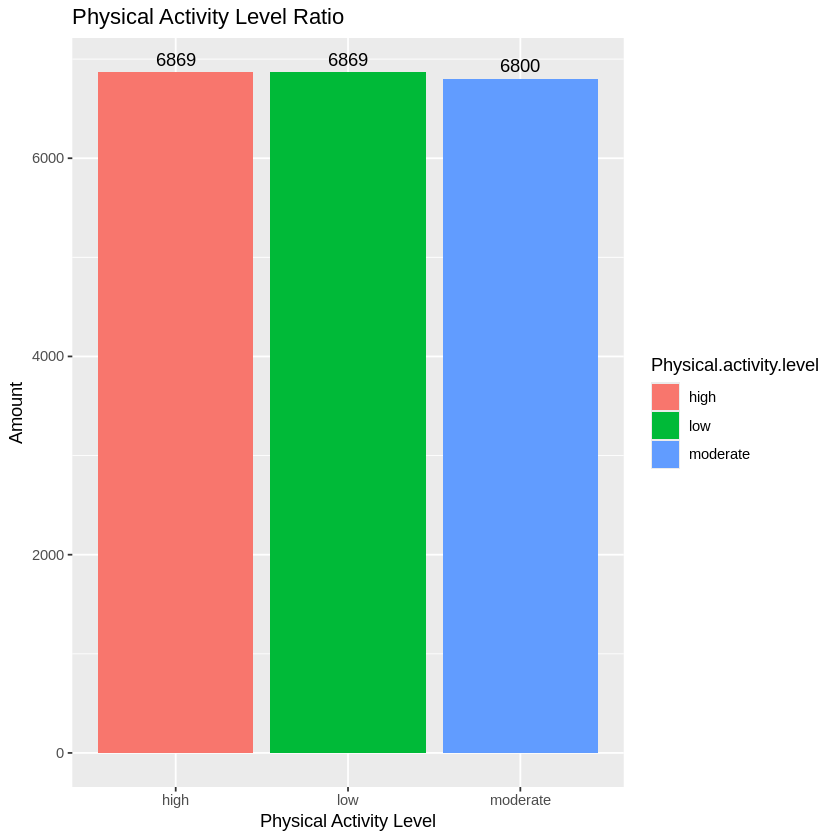

In [ ]:
ggplot(df_raw, aes(x = Physical.activity.level, fill = Physical.activity.level)) +
  geom_bar() + xlab("Physical Activity Level") + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) +  ylab("Amount") +
  ggtitle("Physical Activity Level Ratio")

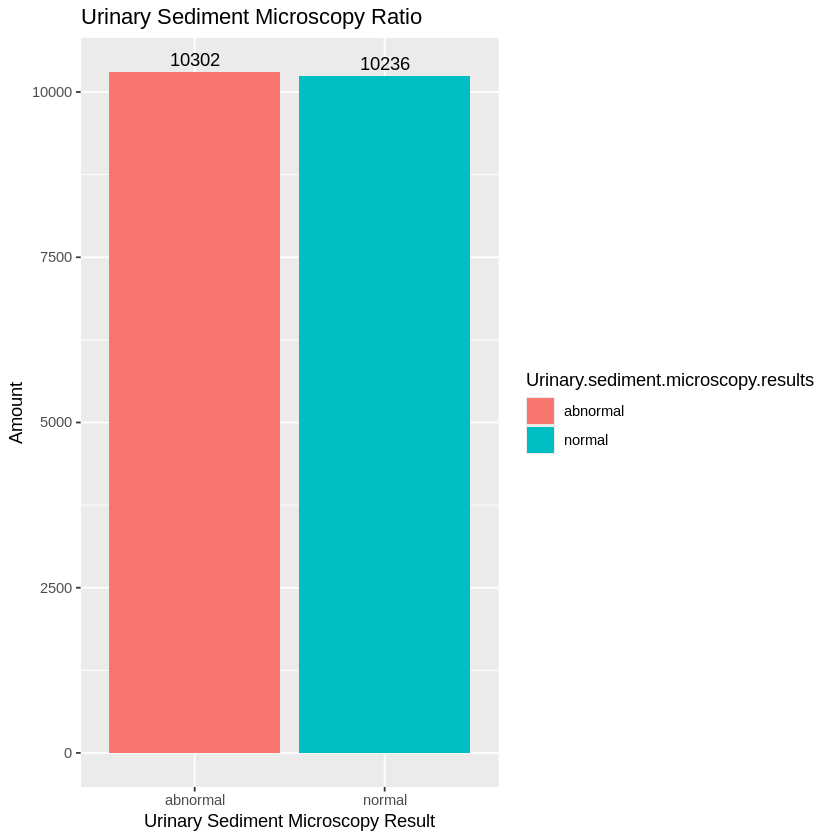

In [ ]:
ggplot(df_raw, aes(x = Urinary.sediment.microscopy.results, fill = Urinary.sediment.microscopy.results)) +
  geom_bar() + xlab("Urinary Sediment Microscopy Result") + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) +  ylab("Amout") +ylab("Amount") +
  ggtitle("Urinary Sediment Microscopy Ratio")

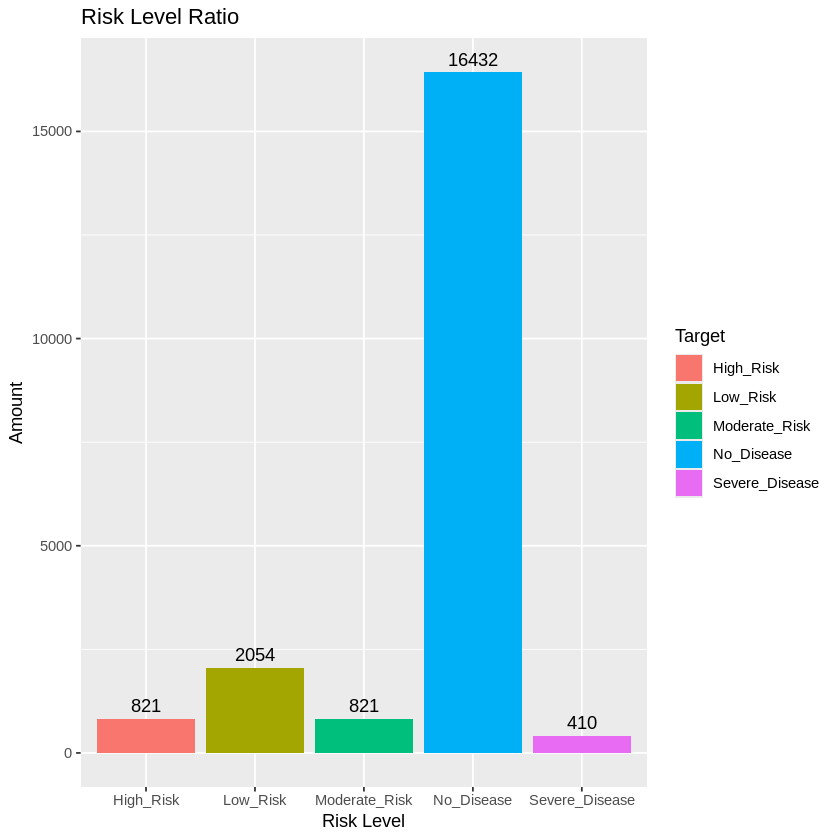

In [ ]:
ggplot(df_raw, aes(x = Target, fill = Target)) +
  geom_bar() + xlab("Risk Level") + geom_text(stat='count', aes(label = after_stat(count)), vjust=-0.5) + ylab("Amount") +
  ggtitle("Risk Level Ratio")

In [ ]:
df_clean <- df_raw

In [ ]:
df_clean$White.blood.cell.count..cells.cumm. <- scale(df_clean$White.blood.cell.count..cells.cumm.)
df_clean$Urine.output..ml.day. <- scale(df_clean$Urine.output..ml.day.)
df_clean$Blood.pressure..mm.Hg. <- scale(df_clean$Blood.pressure..mm.Hg.)
df_clean$Random.blood.glucose.level..mg.dl. <- scale(df_clean$Random.blood.glucose.level..mg.dl.)
df_clean$Sodium.level..mEq.L. <- scale(df_clean$Sodium.level..mEq.L.)
df_clean$Cholesterol.level <- scale(df_clean$Cholesterol.level)
df_clean$Blood.urea..mg.dl. <- scale(df_clean$Blood.urea..mg.dl.)
str(df_clean)

'data.frame':	20538 obs. of  43 variables:
 $ Age.of.the.patient                         : int  54 42 38 7 67 14 9 67 42 23 ...
 $ Blood.pressure..mm.Hg.                     : num [1:20538, 1] 1.261 -0.115 0.607 -1.113 1.502 ...
  ..- attr(*, "scaled:center")= num 130
  ..- attr(*, "scaled:scale")= num 29.1
 $ Specific.gravity.of.urine                  : num  1.02 1.02 1.02 1.02 1.01 ...
 $ Albumin.in.urine                           : int  1 3 0 4 1 4 2 5 4 2 ...
 $ Sugar.in.urine                             : int  4 2 0 0 1 2 0 3 4 4 ...
 $ Red.blood.cells.in.urine                   : chr  "normal" "normal" "abnormal" "abnormal" ...
 $ Pus.cells.in.urine                         : chr  "abnormal" "normal" "normal" "normal" ...
 $ Pus.cell.clumps.in.urine                   : chr  "not present" "not present" "not present" "not present" ...
 $ Bacteria.in.urine                          : chr  "not present" "present" "not present" "present" ...
 $ Random.blood.glucose.level..mg.dl.        

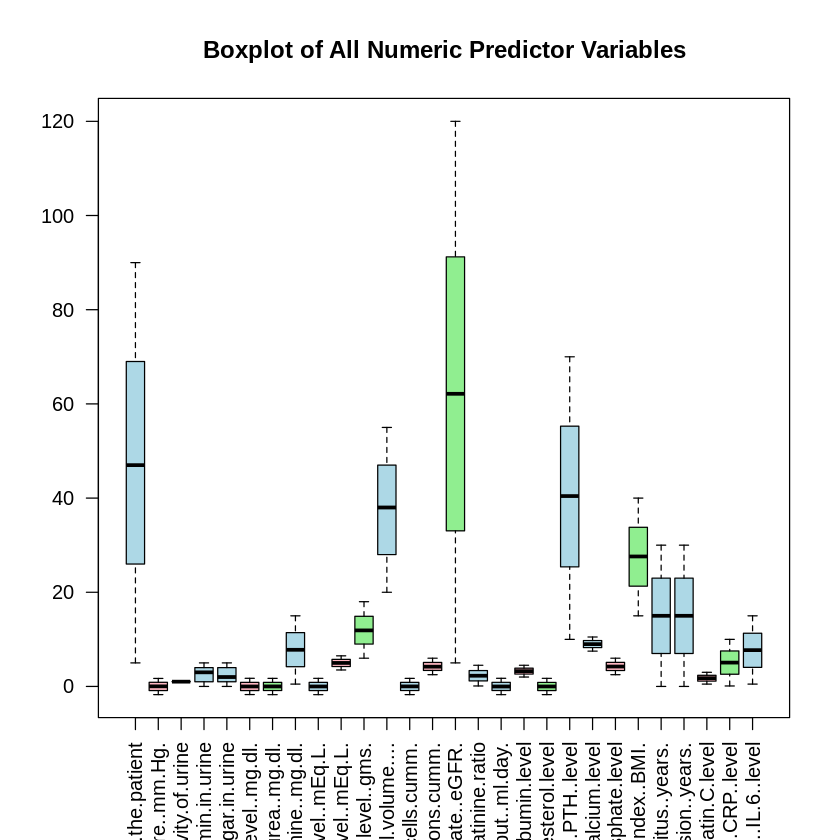

In [ ]:
df_cleanbox <- df_clean[, sapply(df_clean, is.numeric)]
boxplot(df_cleanbox,
        col = c("lightblue", "lightpink", "lightgreen", "lightblue"),
        main = "Boxplot of All Numeric Predictor Variables",
        border = "black",
        notch = FALSE,
        las = 2)

In [ ]:
df_clean$Physical.activity.level <- as.numeric(factor(df_clean$Physical.activity.level, levels = c("low", "moderate", "high")))
df_clean$Red.blood.cells.in.urine <- ifelse(df_clean$Red.blood.cells.in.urine == "normal", 1, 0)
df_clean$Pus.cells.in.urine <- ifelse(df_clean$Pus.cells.in.urine == "normal", 1, 0)
df_clean$Pus.cell.clumps.in.urine <- ifelse(df_clean$Pus.cell.clumps.in.urine == "present", 1, 0)
df_clean$Bacteria.in.urine <- ifelse(df_clean$Bacteria.in.urine == "present", 1, 0)
df_clean$Hypertension..yes.no. <- ifelse(df_clean$Hypertension..yes.no. == "yes", 1, 0)
df_clean$Diabetes.mellitus..yes.no. <- ifelse(df_clean$Diabetes.mellitus..yes.no. == "yes", 1, 0)
df_clean$Coronary.artery.disease..yes.no. <- ifelse(df_clean$Coronary.artery.disease..yes.no. == "yes", 1, 0)
df_clean$Appetite..good.poor. <- ifelse(df_clean$Appetite..good.poor. == "good", 1, 0)
df_clean$Pedal.edema..yes.no. <- ifelse(df_clean$Pedal.edema..yes.no. == "yes", 1, 0)
df_clean$Anemia..yes.no. <- ifelse(df_clean$Anemia..yes.no. == "yes", 1, 0)
df_clean$Family.history.of.chronic.kidney.disease <- ifelse(df_clean$Family.history.of.chronic.kidney.disease == "yes", 1, 0)
df_clean$Smoking.status <- ifelse(df_clean$Smoking.status == "yes", 1, 0)
df_clean$Urinary.sediment.microscopy.results <- ifelse(df_clean$Urinary.sediment.microscopy.results == "normal", 1, 0)
df_clean$Target <- as.factor(df_clean$Target)

In [ ]:
str(df_clean)

'data.frame':	20538 obs. of  43 variables:
 $ Age.of.the.patient                         : int  54 42 38 7 67 14 9 67 42 23 ...
 $ Blood.pressure..mm.Hg.                     : num [1:20538, 1] 1.261 -0.115 0.607 -1.113 1.502 ...
  ..- attr(*, "scaled:center")= num 130
  ..- attr(*, "scaled:scale")= num 29.1
 $ Specific.gravity.of.urine                  : num  1.02 1.02 1.02 1.02 1.01 ...
 $ Albumin.in.urine                           : int  1 3 0 4 1 4 2 5 4 2 ...
 $ Sugar.in.urine                             : int  4 2 0 0 1 2 0 3 4 4 ...
 $ Red.blood.cells.in.urine                   : num  1 1 0 0 1 0 0 1 0 0 ...
 $ Pus.cells.in.urine                         : num  0 1 1 1 0 0 1 1 1 0 ...
 $ Pus.cell.clumps.in.urine                   : num  0 0 0 0 0 0 0 1 1 0 ...
 $ Bacteria.in.urine                          : num  0 1 0 1 0 1 0 1 1 1 ...
 $ Random.blood.glucose.level..mg.dl.         : num [1:20538, 1] -1.513 -1.698 -1.666 -0.478 0.733 ...
  ..- attr(*, "scaled:center")= num 285
  ..

In [ ]:
model1 <- polr(Target ~ ., data = df_clean, Hess = TRUE)
summary(model1)

Call:
polr(formula = Target ~ ., data = df_clean, Hess = TRUE)

Coefficients:
                                                Value Std. Error  t value
Age.of.the.patient                           0.001012  0.0006958  1.45493
Blood.pressure..mm.Hg.                      -0.012952  0.0173547 -0.74630
Specific.gravity.of.urine                    5.044546  0.1507867 33.45485
Albumin.in.urine                            -0.013375  0.0102369 -1.30651
Sugar.in.urine                              -0.002173  0.0102119 -0.21276
Red.blood.cells.in.urine                     0.040020  0.0347296  1.15232
Pus.cells.in.urine                           0.131237  0.0347530  3.77628
Pus.cell.clumps.in.urine                    -0.003357  0.0347003 -0.09675
Bacteria.in.urine                           -0.016074  0.0347049 -0.46316
Random.blood.glucose.level..mg.dl.           0.006832  0.0173649  0.39341
Blood.urea..mg.dl.                          -0.002874  0.0173581 -0.16560
Serum.creatinine..mg.dl.          

In [ ]:
summary_df <- as.data.frame(summary(model1)$coefficients)
summary_df$Variable <- rownames(summary_df)
rownames(summary_df) <- NULL

write.csv(summary_df, "model_summary.csv", row.names = FALSE)

In [ ]:
ctable <- coef(summary(model1)); ctable

,Value,Std. Error,t value
Age.of.the.patient,0.0010123997,0.0006958385,1.45493492
Blood.pressure..mm.Hg.,-0.0129517496,0.0173547025,-0.74629626
Specific.gravity.of.urine,5.0445457585,0.1507866793,33.45485013
Albumin.in.urine,-0.0133746069,0.0102368802,-1.30651201
Sugar.in.urine,-0.0021727088,0.0102118656,-0.21276316
Red.blood.cells.in.urine,0.0400196047,0.0347296277,1.15231885
Pus.cells.in.urine,0.1312369417,0.0347529619,3.77628077
Pus.cell.clumps.in.urine,-0.0033572229,0.0347003111,-0.09674907
Bacteria.in.urine,-0.0160740462,0.0347049344,-0.46316313
Random.blood.glucose.level..mg.dl.,0.0068316155,0.0173649320,0.39341447


In [ ]:
pwald <- pnorm(abs(ctable[,"t value"]), lower.tail = FALSE)*2
ctable1 <- cbind(ctable, "p value" = pwald); ctable1
ctable1$Variable <- rownames(ctable1)
rownames(ctable1) <- NULL

write.csv(ctable1, "p_wald_table.csv", row.names = FALSE)

,Value,Std. Error,t value,p value
Age.of.the.patient,0.0010123997,0.0006958385,1.45493492,1.456873e-01
Blood.pressure..mm.Hg.,-0.0129517496,0.0173547025,-0.74629626,4.554885e-01
Specific.gravity.of.urine,5.0445457585,0.1507866793,33.45485013,2.187960e-245
Albumin.in.urine,-0.0133746069,0.0102368802,-1.30651201,1.913785e-01
Sugar.in.urine,-0.0021727088,0.0102118656,-0.21276316,8.315117e-01
Red.blood.cells.in.urine,0.0400196047,0.0347296277,1.15231885,2.491901e-01
Pus.cells.in.urine,0.1312369417,0.0347529619,3.77628077,1.591875e-04
Pus.cell.clumps.in.urine,-0.0033572229,0.0347003111,-0.09674907,9.229257e-01
Bacteria.in.urine,-0.0160740462,0.0347049344,-0.46316313,6.432474e-01
Random.blood.glucose.level..mg.dl.,0.0068316155,0.0173649320,0.39341447,6.940134e-01


Warning message in ctable1$Variable <- rownames(ctable1):
“Coercing LHS to a list”


In [ ]:
# LRT

model_null <- polr(Target ~ 1, data = df_clean, Hess = TRUE)
summary(model_null)

Call:
polr(formula = Target ~ 1, data = df_clean, Hess = TRUE)

No coefficients

Intercepts:
                          Value    Std. Error t value 
High_Risk|Low_Risk         -3.1787   0.0356   -89.2411
Low_Risk|Moderate_Risk     -1.8154   0.0201   -90.2712
Moderate_Risk|No_Disease   -1.5166   0.0182   -83.4952
No_Disease|Severe_Disease   3.8937   0.0499    78.0507

Residual Deviance: 30571.05 
AIC: 30579.05 

In [ ]:
LRT <- anova(model_null, model1, test = 'Chisq')
LRT$Model <- c("NULL", "FULL")

In [ ]:
LRT

write.csv(LRT, "LRT_Table.csv", row.names = FALSE)

Model,Resid. df,Resid. Dev,Test,Df,LR stat.,Pr(Chi)
<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
NULL,20534,30571.05,,NA,NA,NA
FULL,20492,30515.45,1 vs 2,42,55.60834,0.07776217


In [ ]:
install.packages("caret")
library(caret)

model_predict <- predict(model1, data = df_clean, type = "class")
conf_mat <- confusionMatrix(model_predict, df_clean$Target)
conf_mat$overall
print(conf_mat)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘pROC’, ‘recipes’


Loading required package: lattice



Accuracy          Kappa  AccuracyLower  AccuracyUpper   AccuracyNull 
     0.8000779      0.0000000      0.7945415      0.8055292      0.8000779 
AccuracyPValue  McnemarPValue 
     0.5041763            NaN

Confusion Matrix and Statistics

                Reference
Prediction       High_Risk Low_Risk Moderate_Risk No_Disease Severe_Disease
  High_Risk              0        0             0          0              0
  Low_Risk               0        0             0          0              0
  Moderate_Risk          0        0             0          0              0
  No_Disease           821     2054           821      16432            410
  Severe_Disease         0        0             0          0              0

Overall Statistics
                                          
               Accuracy : 0.8001          
                 95% CI : (0.7945, 0.8055)
    No Information Rate : 0.8001          
    P-Value [Acc > NIR] : 0.5042          
                                          
                  Kappa : 0               
                                          
 Mcnemar's Test P-Value : NA              

Statistics by Class:

                     Class: High_Risk Class: Low_Risk C